<a href="https://colab.research.google.com/github/onszayani/driver-fatigue-detection/blob/main/notebooks/e1_exploration_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
!python --version
!pip freeze | grep -E "torch|tensorflow|opencv|mediapipe|numpy"

Python 3.13.16
numpy==2.4.6
opencv-contrib-python==4.14.0.94
opencv-python==5.0.0.93
opencv-python-headless==5.0.0.93
tensorflow==2.21.0
tensorflow-datasets==4.9.10
tensorflow-hub==0.16.1
tensorflow-metadata==1.21.0
tensorflow-probability==0.25.0
tensorflow-text==2.21.1
torch==2.14.1+cu130
torchao==0.10.0
torchaudio==2.11.0+cu130
torchcodec==0.17.0+cu130
torchdata==0.11.0
torchsummary==1.5.1
torchtune==0.6.1
torchvision==0.29.1+cu130


In [3]:
!pip install -q kaggle
!kaggle datasets download -d imadeddinedjerarda/mrl-eye-dataset -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/imadeddinedjerarda/mrl-eye-dataset
License(s): unknown
100% 330M/330M [00:18<00:00, 18.4MB/s]



In [4]:
import os
for racine, dossiers, fichiers in os.walk('/content/data'):
    print(racine, '->', len(dossiers), 'dossiers,', len(fichiers), 'fichiers')
    if racine.count('/') > 4:
        break

/content/data -> 1 dossiers, 0 fichiers
/content/data/mrleyedataset -> 2 dossiers, 0 fichiers
/content/data/mrleyedataset/Close-Eyes -> 0 dossiers, 41946 fichiers
/content/data/mrleyedataset/Open-Eyes -> 0 dossiers, 42952 fichiers


In [5]:
!kaggle datasets download -d imadeddinedjerarda/mrl-eye-dataset -p /content/drive/MyDrive/fatigue_project

Dataset URL: https://www.kaggle.com/datasets/imadeddinedjerarda/mrl-eye-dataset
License(s): unknown
mrl-eye-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [6]:
import os
for racine, dossiers, fichiers in os.walk('/content/data'):
    print(racine, '->', len(dossiers), 'dossiers,', len(fichiers), 'fichiers')
    if racine.count('/') > 5:
        break

/content/data -> 1 dossiers, 0 fichiers
/content/data/mrleyedataset -> 2 dossiers, 0 fichiers
/content/data/mrleyedataset/Close-Eyes -> 0 dossiers, 41946 fichiers
/content/data/mrleyedataset/Open-Eyes -> 0 dossiers, 42952 fichiers


In [7]:
import glob
chemins = glob.glob('/content/data/**/*.png', recursive=True) + glob.glob('/content/data/**/*.jpg', recursive=True)
print("Nombre total d'images :", len(chemins))
for c in chemins[:10]:
    print(c)

Nombre total d'images : 84898
/content/data/mrleyedataset/Close-Eyes/s0037_00657_1_0_0_0_0_01.png
/content/data/mrleyedataset/Close-Eyes/s0031_00020_1_0_0_0_1_02.png
/content/data/mrleyedataset/Close-Eyes/s0006_00953_0_1_0_1_0_01.png
/content/data/mrleyedataset/Close-Eyes/s0014_00349_0_0_0_0_0_01.png
/content/data/mrleyedataset/Close-Eyes/s0012_00652_0_0_0_0_1_01.png
/content/data/mrleyedataset/Close-Eyes/s0001_01432_0_1_0_2_0_01.png
/content/data/mrleyedataset/Close-Eyes/s0019_02859_0_0_0_0_0_01.png
/content/data/mrleyedataset/Close-Eyes/s0014_01693_0_0_0_0_0_01.png
/content/data/mrleyedataset/Close-Eyes/s0019_02388_0_0_0_0_1_01.png
/content/data/mrleyedataset/Close-Eyes/s0011_01150_0_0_0_0_0_01.png


{'Close-Eyes': 41946, 'Open-Eyes': 42952}


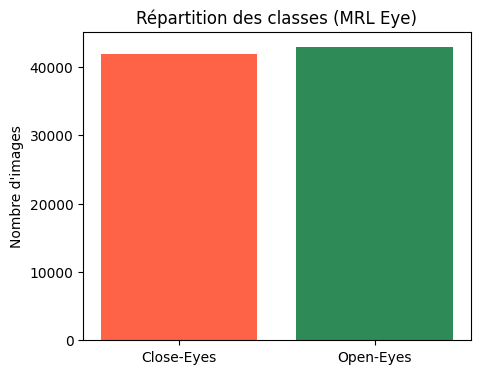

In [8]:
import os, glob
import matplotlib.pyplot as plt

base = '/content/data/mrleyedataset'
classes = ['Close-Eyes', 'Open-Eyes']
nb = {c: len(os.listdir(f'{base}/{c}')) for c in classes}
print(nb)

plt.figure(figsize=(5,4))
plt.bar(nb.keys(), nb.values(), color=['tomato', 'seagreen'])
plt.title("Répartition des classes (MRL Eye)")
plt.ylabel("Nombre d'images")
os.makedirs('/content/drive/MyDrive/fatigue_project/figures', exist_ok=True)
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/repartition_classes.png', dpi=150, bbox_inches='tight')
plt.show()

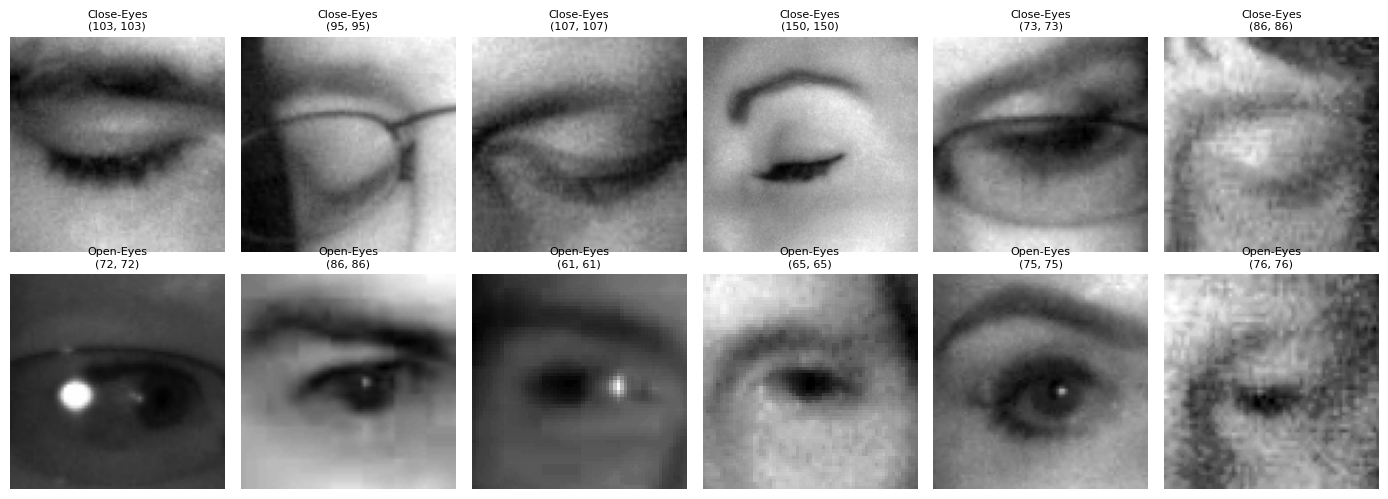

In [9]:
import random
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ligne, c in enumerate(classes):
    fichiers = random.sample(os.listdir(f'{base}/{c}'), 6)
    for col, f in enumerate(fichiers):
        img = Image.open(f'{base}/{c}/{f}')
        axes[ligne, col].imshow(img, cmap='gray')
        axes[ligne, col].set_title(f"{c}\n{img.size}", fontsize=8)
        axes[ligne, col].axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/exemples.png', dpi=150, bbox_inches='tight')
plt.show()

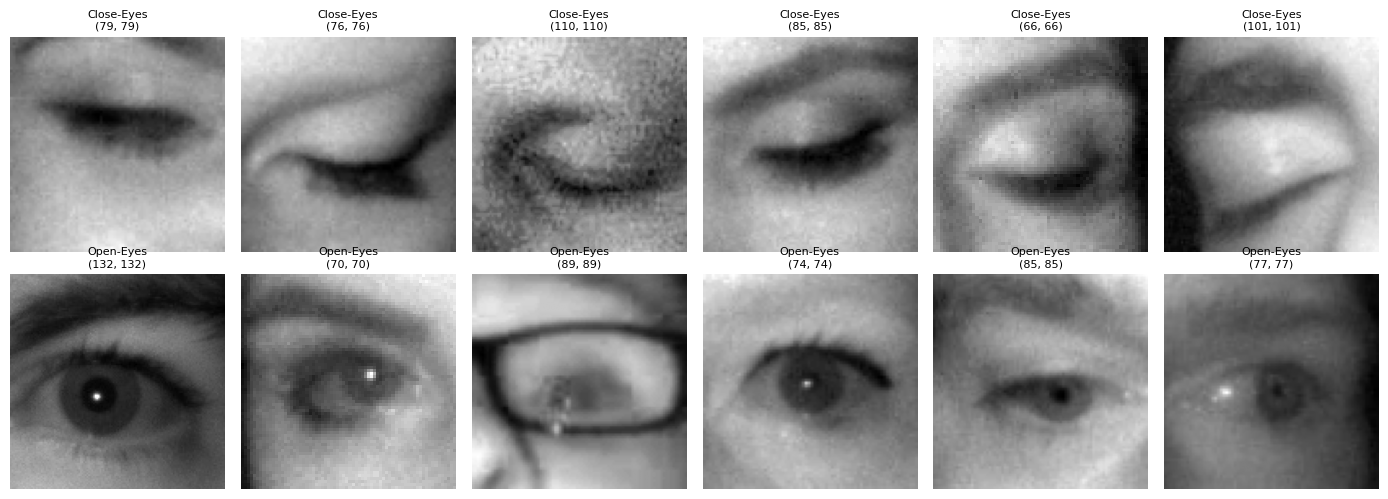

In [10]:
import random
from PIL import Image

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for ligne, c in enumerate(classes):
    fichiers = random.sample(os.listdir(f'{base}/{c}'), 6)
    for col, f in enumerate(fichiers):
        img = Image.open(f'{base}/{c}/{f}')
        axes[ligne, col].imshow(img, cmap='gray')
        axes[ligne, col].set_title(f"{c}\n{img.size}", fontsize=8)
        axes[ligne, col].axis('off')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/fatigue_project/figures/exemples.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
import pandas as pd

lignes = []
for c in classes:
    for f in os.listdir(f'{base}/{c}'):
        p = f.split('_')
        lignes.append({'fichier': f, 'dossier': c, 'sujet': p[0],
                       'genre': p[2], 'lunettes': p[3], 'etat_champ': p[4]})
df = pd.DataFrame(lignes)

print("Nombre de personnes :", df['sujet'].nunique())
print("\nImages par personne (résumé) :")
print(df['sujet'].value_counts().describe())
print("\nLunettes (0/1) :")
print(df['lunettes'].value_counts())
print("\nDossier vs champ d'état dans le nom :")
print(pd.crosstab(df['dossier'], df['etat_champ']))

Nombre de personnes : 37

Images par personne (résumé) :
count       37.000000
mean      2294.540541
std       2659.071931
min        382.000000
25%        704.000000
50%       1114.000000
75%       1889.000000
max      10257.000000
Name: count, dtype: float64

Lunettes (0/1) :
lunettes
0    60897
1    24001
Name: count, dtype: int64

Dossier vs champ d'état dans le nom :
etat_champ      0      1
dossier                 
Close-Eyes  41946      0
Open-Eyes       0  42952


In [12]:
import random, json

par_sujet = df.groupby('sujet').agg(
    n=('fichier', 'size'),
    fermes=('etat_champ', lambda x: (x == '0').sum()),
    lunettes=('lunettes', lambda x: (x == '1').sum()),
)
sujets = sorted(par_sujet.index)
total = par_sujet.sum()
cibles = {'train': 0.70, 'val': 0.15, 'test': 0.15}
tailles = {'train': 25, 'val': 6, 'test': 6}   # 25 + 6 + 6 = 37 personnes

def tirage(seed):
    s = sujets[:]
    random.Random(seed).shuffle(s)
    parts = {'train': s[:25], 'val': s[25:31], 'test': s[31:]}
    ecart = 0
    for nom, liste in parts.items():
        t = par_sujet.loc[liste].sum()
        ecart += abs(t['n'] / total['n'] - cibles[nom])
        ecart += abs(t['fermes'] / t['n'] - total['fermes'] / total['n'])
        ecart += abs(t['lunettes'] / t['n'] - total['lunettes'] / total['n'])
    return ecart, parts

meilleure = min(range(5000), key=lambda sd: tirage(sd)[0])
ecart, parts = tirage(meilleure)
print("Seed retenue :", meilleure, "| écart :", round(ecart, 3))

for nom, liste in parts.items():
    t = par_sujet.loc[liste].sum()
    print(f"{nom:5s}: {len(liste):2d} personnes, {t['n']:6d} images "
          f"({t['n']/total['n']:.0%}), yeux fermés {t['fermes']/t['n']:.0%}, "
          f"lunettes {t['lunettes']/t['n']:.0%}")

# Vérification : aucune personne dans deux groupes
assert not (set(parts['train']) & set(parts['val']))
assert not (set(parts['train']) & set(parts['test']))
assert not (set(parts['val']) & set(parts['test']))
print("OK : aucune personne n'est dans deux groupes.")

Seed retenue : 926 | écart : 0.12
train: 25 personnes,  59109 images (70%), yeux fermés 48%, lunettes 28%
val  :  6 personnes,  13462 images (16%), yeux fermés 54%, lunettes 27%
test :  6 personnes,  12327 images (15%), yeux fermés 51%, lunettes 30%
OK : aucune personne n'est dans deux groupes.


In [13]:
os.makedirs('/content/drive/MyDrive/fatigue_project', exist_ok=True)
decoupage = {'seed': meilleure, 'train': parts['train'], 'val': parts['val'], 'test': parts['test']}
with open('/content/drive/MyDrive/fatigue_project/splits.json', 'w') as f:
    json.dump(decoupage, f, indent=2)

from google.colab import files
with open('splits.json', 'w') as f:
    json.dump(decoupage, f, indent=2)
files.download('splits.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
os.makedirs('/content/drive/MyDrive/fatigue_project', exist_ok=True)
decoupage = {'seed': meilleure, 'train': parts['train'], 'val': parts['val'], 'test': parts['test']}
with open('/content/drive/MyDrive/fatigue_project/splits.json', 'w') as f:
    json.dump(decoupage, f, indent=2)

from google.colab import files
with open('splits.json', 'w') as f:
    json.dump(decoupage, f, indent=2)
files.download('splits.json')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>